In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

In [2]:
df = pd.read_excel(r"C:\Users\Dell\Downloads\Processed_Flipdata.xlsx")

In [3]:
df.shape

(541, 12)

In [4]:
df.head()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


In [5]:
df.tail()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,79999
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,5998
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,9990
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core",38999
540,642,OPPO A77,Sky Blue,128,4,5000,50MP,8MP,0,16.66,Mediatek Helio G35,15999


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 50.8+ KB


In [7]:
df.describe()

,Unnamed: 0,Memory,RAM,Battery_,AI Lens,Mobile Height,Prize
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,289.711645,110.550832,5.397412,4871.587800,0.062847,16.431201,16228.375231
std,182.359185,60.600694,1.984923,780.148862,0.242911,2.523553,10793.588322
min,0.000000,16.000000,2.000000,800.000000,0.000000,4.500000,920.000000
25%,135.000000,64.000000,4.000000,5000.000000,0.000000,16.510000,9290.000000
50%,273.000000,128.000000,6.000000,5000.000000,0.000000,16.710000,13499.000000
75%,434.000000,128.000000,8.000000,5000.000000,0.000000,16.940000,19280.000000
max,642.000000,256.000000,8.000000,7000.000000,1.000000,41.940000,80999.000000


In [8]:
df.isnull().sum()

Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64

In [9]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

In [10]:
df = df.rename(columns={"Prize": "Price"})
df = df.rename(columns={"Battery_": "Battery"})
df = df.rename(columns={"Processor_": "Processor"})

In [11]:
df = df.drop_duplicates()

In [12]:
df["Rear Camera"] = df["Rear Camera"].str.replace("MP", "")
df["Rear Camera"] = df["Rear Camera"].astype(int)

In [13]:
df["Front Camera"] = df["Front Camera"].str.replace("MP", "")
df["Front Camera"] = df["Front Camera"].astype(int)

In [14]:
df["Brand"] = df["Model"].str.split().str[0]
df["Brand"] = df["Brand"].str.title()

In [15]:
df = df[df["Mobile Height"] < 30]

In [16]:
df.shape

(529, 12)

In [17]:
X = df.drop(columns=["Price", "Model", "Colour", "Processor"])
X = pd.get_dummies(X)
y = df["Price"]

Price            1.000000
Memory           0.563601
RAM              0.531102
Front Camera     0.529173
Rear Camera      0.406787
Mobile Height    0.215598
Battery         -0.046264
AI Lens         -0.156338
Name: Price, dtype: float64


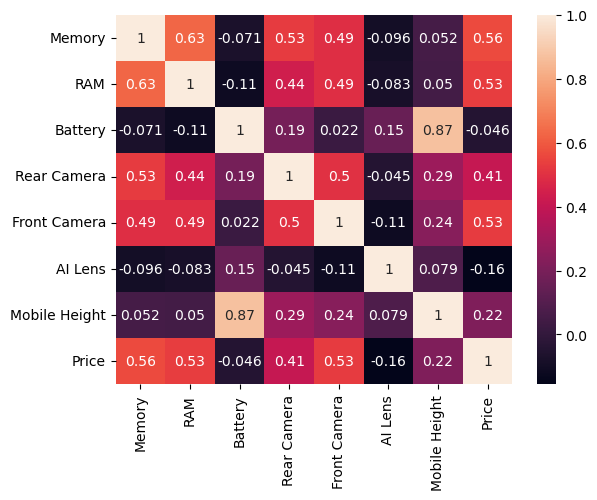

In [18]:
print(df.corr(numeric_only=True)["Price"].sort_values(ascending=False))

sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

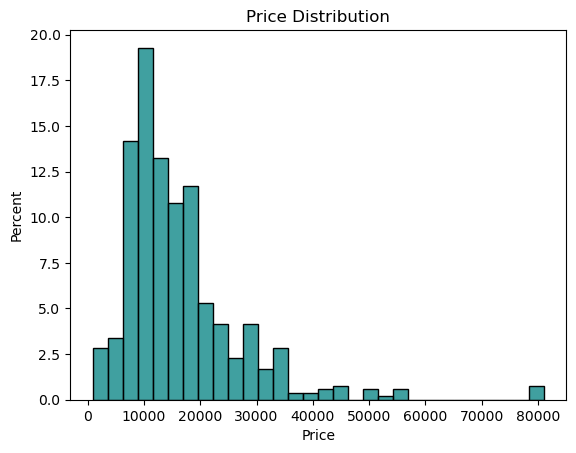

In [19]:
sns.histplot(df["Price"], bins=30, color="teal", edgecolor="black", stat="percent")
plt.title("Price Distribution")
plt.show()

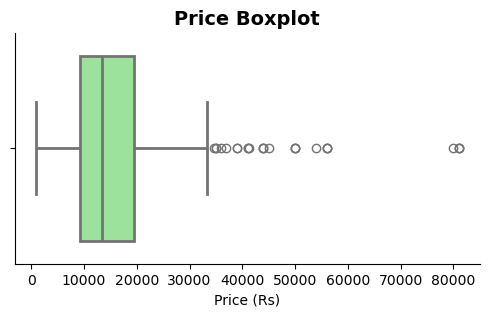

In [20]:
plt.figure(figsize=(6,3))
sns.boxplot(x=df["Price"], color="lightgreen", linewidth=2, fliersize=6)
plt.title("Price Boxplot", fontsize=14, fontweight="bold")
plt.xlabel("Price (Rs)")
sns.despine()
plt.show()

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

lr = LinearRegression()
lr.fit(X_train, y_train)

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

for name, model in [("Linear", lr), ("Random Forest", rf)]:
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    rmse = mean_squared_error(y_test, pred) ** 0.5
    r2 = r2_score(y_test, pred)
    print(name, "MAE:", round(mae), "RMSE:", round(rmse), "R2:", round(r2, 2))

Linear MAE: 3047 RMSE: 6507 R2: 0.7
Random Forest MAE: 1593 RMSE: 4035 R2: 0.88


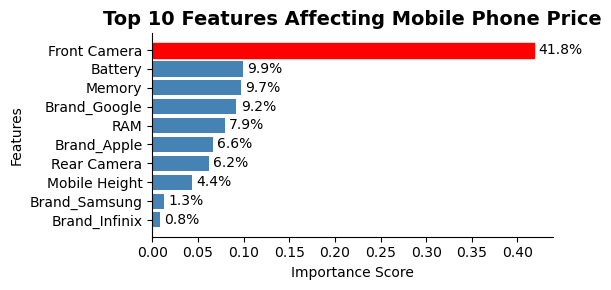

In [24]:
importance = pd.Series(rf.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)
top10 = importance.head(10).sort_values()

plt.figure(figsize=(6,3))
bars = plt.barh(top10.index, top10.values, color="steelblue")
bars[-1].set_color("red")

for bar in bars:
    value = bar.get_width()
    plt.text(value + 0.005, bar.get_y() + 0.2, str(round(value * 100, 1)) + "%")

plt.title("Top 10 Features Affecting Mobile Phone Price", fontsize=14, fontweight="bold")
plt.xlabel("Importance Score")
plt.ylabel("Features")
sns.despine()
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()